# Lab 1 — Data audit
**Concepts:** 1 weld defects and radiographs · 2 train / validation / test split · 3 class imbalance. No model is trained here.

**Why start here.** A radiograph is an X-ray "shadow" of the weld: denser metal stops more X-rays, so voids
(pores), gaps (lack of penetration) and cracks show up as darker or brighter marks. RIAWELC cuts small
tiles out of such radiographs and labels each tile CR (crack), PO (porosity), LP (lack of penetration) or ND (no defect).
Before training anything we need to know: how many tiles per class and split, what each class looks like,
and where the tiles come from. Every later result depends on these facts.

In [1]:
# ---- Setup: identical in every notebook ------------------------------------
# Finds the project folder (Google Drive in Colab, or D:\weld_insp locally),
# makes src/ importable, fixes the random seed.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/weld_insp")
else:
    ROOT = Path(os.environ.get("WELD_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
os.environ["WELD_ROOT"] = str(ROOT)
sys.path.insert(0, str(ROOT / "src"))
QUICK = os.environ.get("WELD_QUICK") == "1"   # tiny smoke-test mode, leave off for real runs

from weld_insp.config import get_paths, set_seed, CLASSES, SEED
P = get_paths()
P.show()
set_seed(SEED)

root          weld_insp
data          weld_insp/data
results       weld_insp/results
figures       weld_insp/results/figures
checkpoints   weld_insp/checkpoints
work          weld_insp/data
riawelc       weld_insp/data/riawelc
gdxray        weld_insp/data/gdxray
gdxray_crops  weld_insp/data/gdxray_crops


## Task 1 — get the data and count it
`get_riawelc` uses `data/riawelc.zip` if you uploaded it. If not, it clones the official repository,
unpacks the 19 RAR parts, and saves `data/riawelc.zip` to Drive so the next session is fast.
In Colab the images are unzipped to `/content` (local disk), which is much faster to read than Drive.

In [2]:
if IN_COLAB:
    !apt-get -qq install -y unrar > /dev/null
from weld_insp.data import get_riawelc, build_image_table
import pandas as pd, numpy as np, matplotlib.pyplot as plt

RIA = get_riawelc(P)
print("Images extracted to", RIA)

Images extracted to weld_insp/data/riawelc


In [3]:
# Folder tree with the number of images in each folder
for split_dir in sorted(p for p in RIA.iterdir() if p.is_dir()):
    print(split_dir.name + "/")
    for cls_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        print(f"    {cls_dir.name:10s} {len(list(cls_dir.glob('*.png'))):6,d} images")

testing/
    Difetto1      765 images
    Difetto2      632 images
    Difetto4      446 images
    NoDifetto     600 images
training/
    Difetto1    4,962 images
    Difetto2    4,108 images
    Difetto4    2,893 images
    NoDifetto   3,900 images
validation/
    Difetto1    1,908 images
    Difetto2    1,580 images
    Difetto4    1,113 images
    NoDifetto   1,500 images


One row per image. Besides path, split, label and file name, the table parses the file name
(plate, section, window, grid position) and stores an MD5 checksum of the file bytes, which Lab 2 uses.

In [4]:
table_f = P.results / "image_table.csv"
if table_f.exists():
    table = pd.read_csv(table_f)
else:
    table = build_image_table(RIA)
    table.to_csv(table_f, index=False)
print(len(table), "rows saved to", table_f)
table.head()

24407 rows saved to weld_insp/results/image_table.csv


,path,split,label,folder,file,plate,section,window,step,row,col,is_copy,radiograph,width,height,md5
0,training/Difetto1/RRT-101R_Img1_A80_S1_[12][8]...,train,CR,Difetto1,RRT-101R_Img1_A80_S1_[12][8].png,RRT-101R,Img1,A80,S1,12,8,False,RRT-101R_Img1,227,227,f2b63591af2950f767c818eef9cb9268
1,training/Difetto1/RRT-101R_Img1_A80_S1_[20][4]...,train,CR,Difetto1,RRT-101R_Img1_A80_S1_[20][4].png,RRT-101R,Img1,A80,S1,20,4,False,RRT-101R_Img1,227,227,d3d31124a7f5bad9a6fc034ef4ec4776
2,training/Difetto1/RRT-101R_Img1_A80_S1_[20][6]...,train,CR,Difetto1,RRT-101R_Img1_A80_S1_[20][6].png,RRT-101R,Img1,A80,S1,20,6,False,RRT-101R_Img1,227,227,b2417d62baf4f098b1ac7a37af36df04
3,training/Difetto1/RRT-101R_Img1_A80_S1_[20][7]...,train,CR,Difetto1,RRT-101R_Img1_A80_S1_[20][7].png,RRT-101R,Img1,A80,S1,20,7,False,RRT-101R_Img1,227,227,68be477de4390ba57734af51379730f7
4,training/Difetto1/RRT-101R_Img1_A80_S1_[24][7]...,train,CR,Difetto1,RRT-101R_Img1_A80_S1_[24][7].png,RRT-101R,Img1,A80,S1,24,7,False,RRT-101R_Img1,227,227,0d858d44e1cc602f969750e4a27801f1


In [5]:
counts = pd.crosstab(table.label, table.split, margins=True, margins_name="total")
counts = counts.loc[["CR", "PO", "LP", "ND", "total"], ["train", "val", "test", "total"]]
counts.to_csv(P.results / "class_counts_original.csv")
print("Total images:", len(table), "(expected 24,407)")
counts

Total images: 24407 (expected 24,407)


split,train,val,test,total
label,,,,
CR,4962,1908,765,7635
PO,4108,1580,632,6320
LP,2893,1113,446,4452
ND,3900,1500,600,6000
total,15863,6101,2443,24407


In [6]:
pct = (pd.crosstab(table.label, table.split, normalize="columns") * 100).round(1)
pct.loc[["CR", "PO", "LP", "ND"], ["train", "val", "test"]]

split,train,val,test
label,,,
CR,31.3,31.3,31.3
PO,25.9,25.9,25.9
LP,18.2,18.2,18.3
ND,24.6,24.6,24.6


In [7]:
# Majority-class baseline: a "lazy model" that always answers the most common class
majority = table[table.split == "train"].label.value_counts().idxmax()
for split in ["train", "val", "test"]:
    acc = (table[table.split == split].label == majority).mean()
    print(f"Always predict {majority}: accuracy on {split:5s} = {acc:.1%}")

Always predict CR: accuracy on train = 31.3%
Always predict CR: accuracy on val   = 31.3%
Always predict CR: accuracy on test  = 31.3%


**Reading this.** Any real model must clearly beat this number. Accuracy alone can hide a model that
ignores the rarest class (LP), which is why later labs report per-class recall and macro-F1.

In [8]:
# Image size check: the README says 224 x 224
table.groupby(["width", "height"]).size().rename("images").to_frame()

,,images
width,height,
227,227,24407


## Task 2 — look at the images

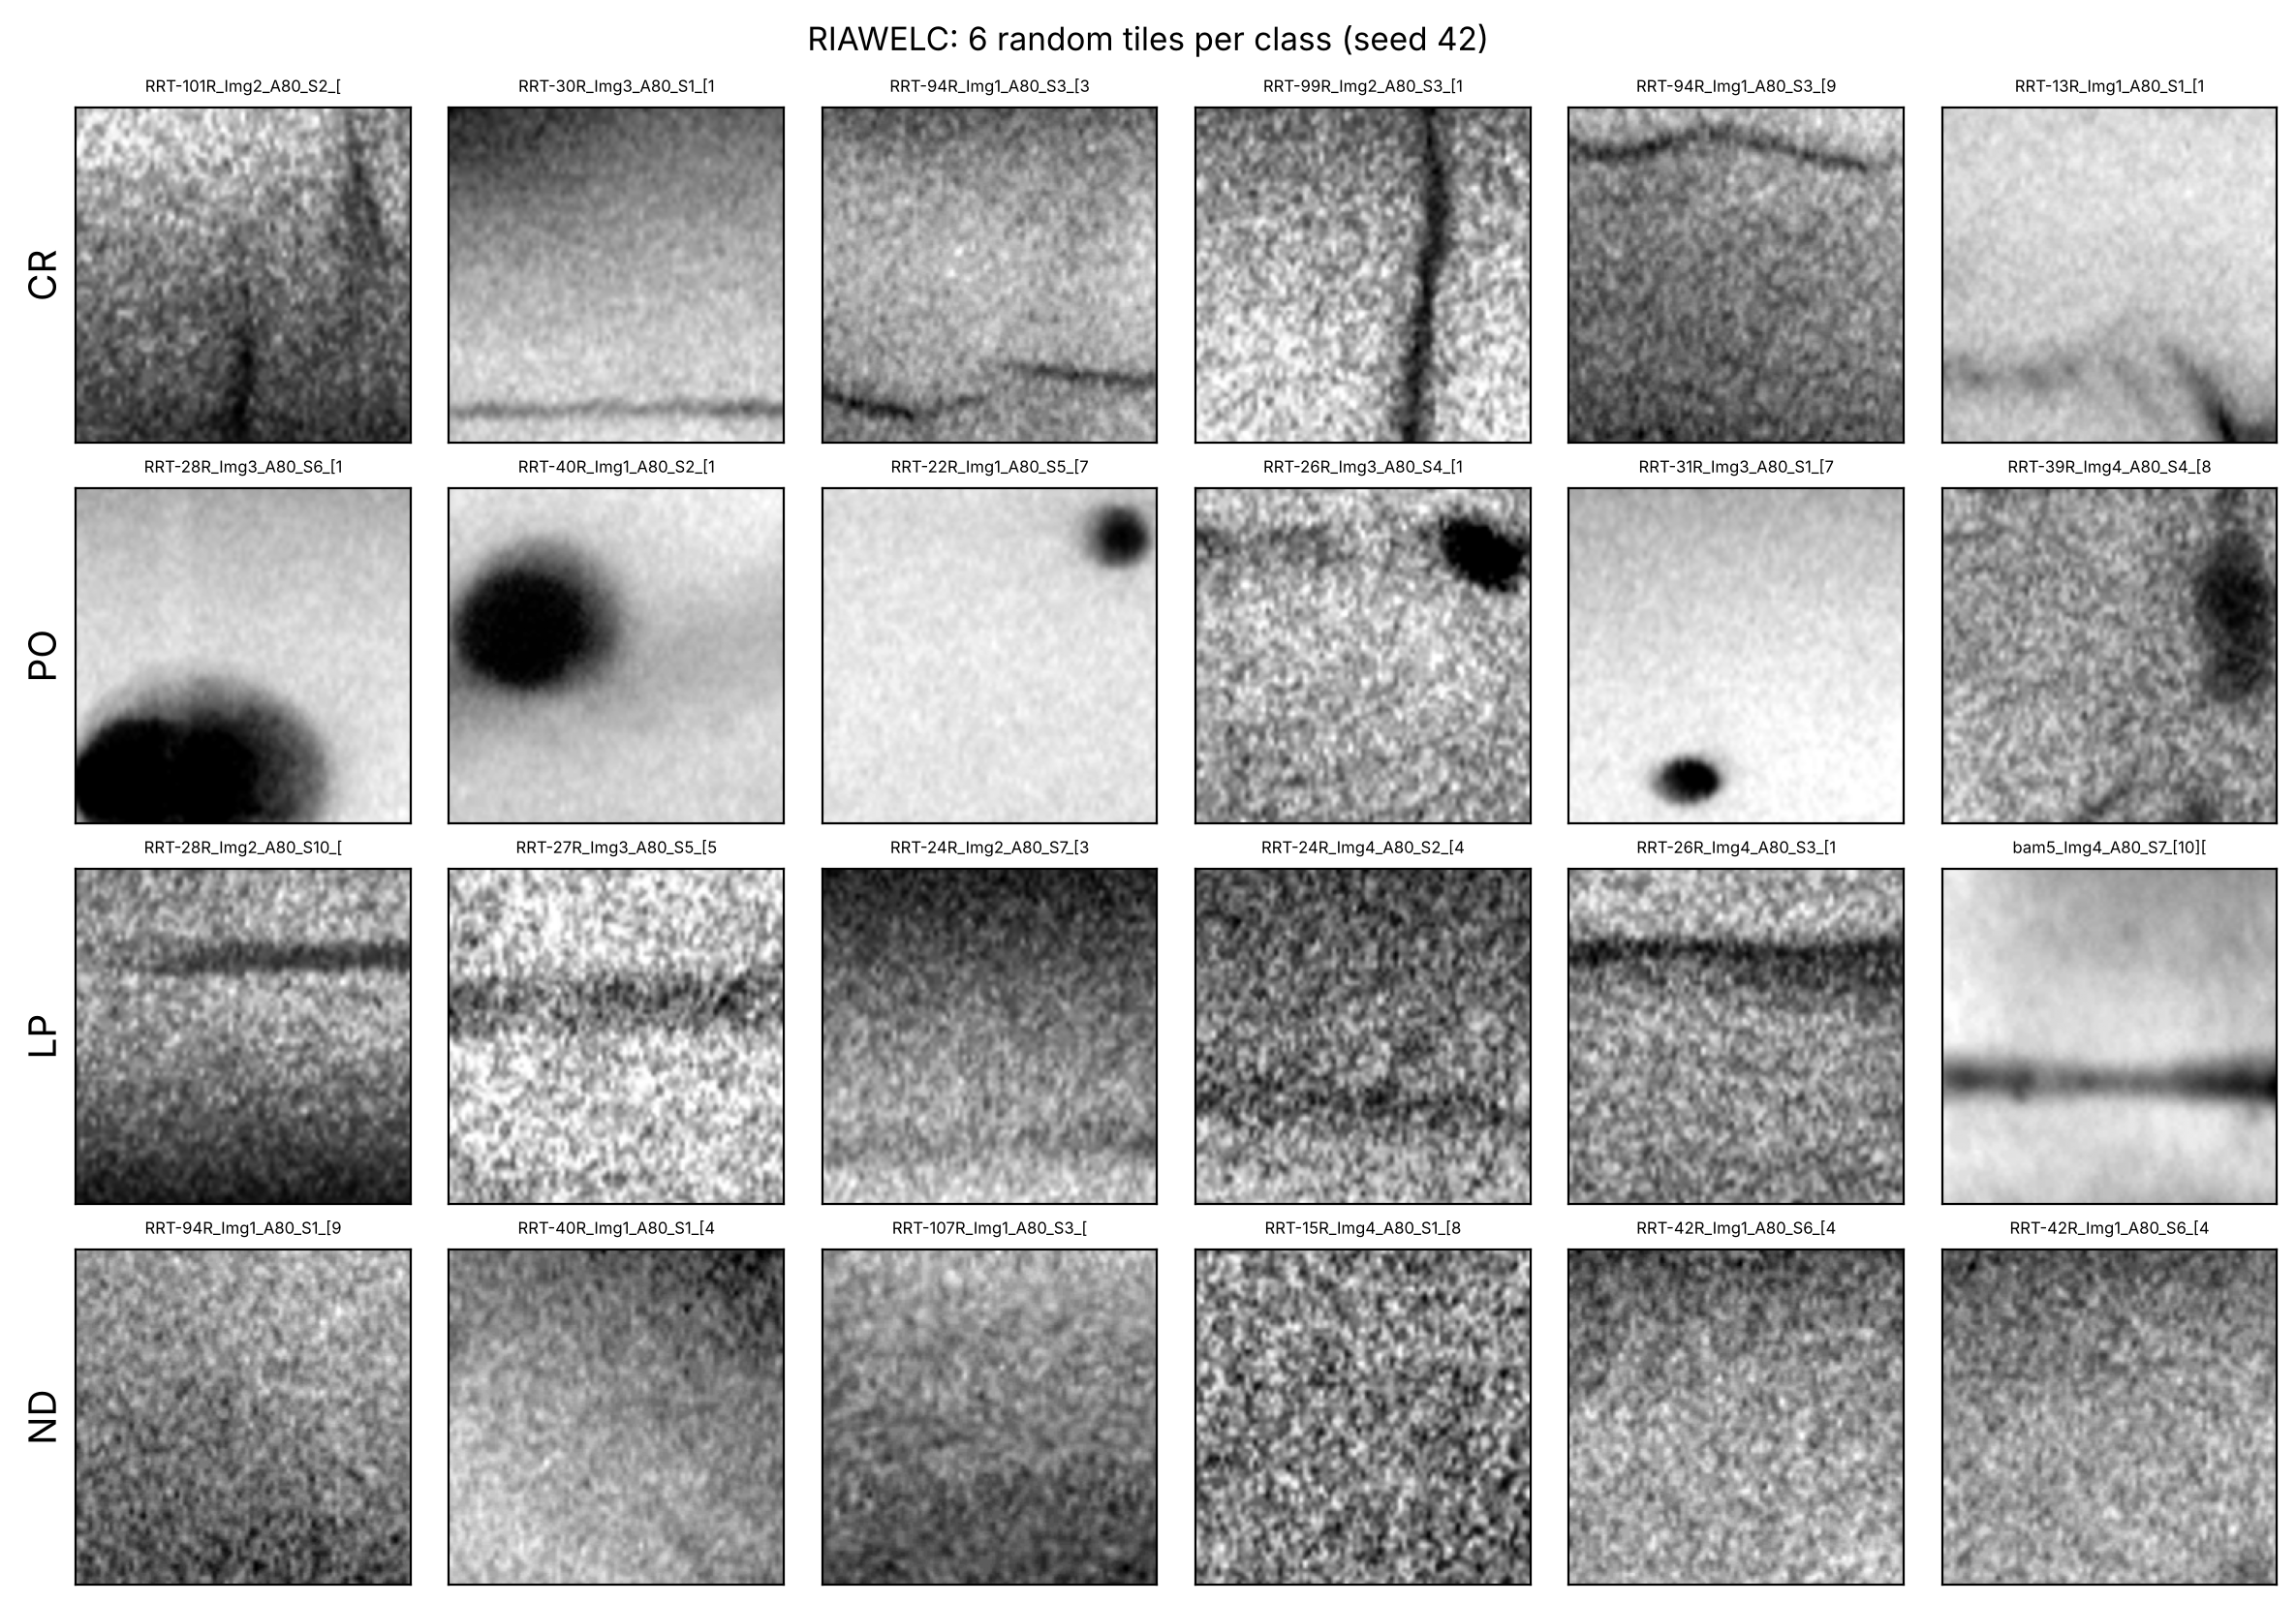

In [9]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
for r, cls in enumerate(["CR", "PO", "LP", "ND"]):
    sub = table[table.label == cls]
    for c, i in enumerate(rng.choice(len(sub), 6, replace=False)):
        row = sub.iloc[i]
        axes[r, c].imshow(plt.imread(RIA / row.path), cmap="gray")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(row.file[:22], fontsize=6)
    axes[r, 0].set_ylabel(cls, fontsize=14)
plt.suptitle("RIAWELC: 6 random tiles per class (seed 42)")
plt.tight_layout()
plt.savefig(P.figures / "01_sample_grid.png", dpi=130)
plt.show()

**What each defect looks like** (one sentence per class, written after looking at the grid):

- **CR (crack):** a thin dark line, sometimes faint, running straight or slightly kinked across the tile in any direction.
- **PO (porosity):** a round or oval dark blob with soft edges, from a few pixels to half the tile wide.
- **LP (lack of penetration):** a horizontal dark band running the full width of the tile, along the weld root.
- **ND (no defect):** grainy weld texture with no isolated mark; brightness changes only gradually across the tile.

The tiles also differ a lot in grain and contrast even within one class, a sign of the CLAHE contrast
enhancement RIAWELC applied and of different source plates.

In [10]:
# Do file names carry a source-radiograph ID?
print(table.file.sample(4, random_state=SEED).tolist())
print("\nDistinct plates (RRT-xxR = BAM Round Robin Test radiograph):", table.plate.nunique())
print("Distinct radiograph sections (plate + Img#):", table.radiograph.nunique())
print("Files marked ' - Copia' (Italian for 'copy'):", int(table.is_copy.sum()))
table.groupby("plate").size().sort_values(ascending=False).head(10).rename("tiles")

['RRT-31R_Img4_A80_S3_[14][12].png', 'RRT-26R_Img4_A80_S4_[9][79].png', 'RRT-27R_Img3_A80_S6_[2][6].png', 'RRT-98R_Img4_A80_S3_[12][8].png']

Distinct plates (RRT-xxR = BAM Round Robin Test radiograph): 29
Distinct radiograph sections (plate + Img#): 109
Files marked ' - Copia' (Italian for 'copy'): 30


plate
RRT-13R    2046
RRT-99R    1900
RRT-26R    1876
RRT-12R    1866
RRT-39R    1821
RRT-94R    1228
RRT-20R    1173
RRT-88R    1164
RRT-40R    1106
RRT-28R    1053
Name: tiles, dtype: int64

**Yes — file names carry a source-radiograph ID.** Example: `RRT-12R_Img1_A80_S2_[6][104].png` =
plate **RRT-12R** (a BAM Round Robin Test radiograph), section **Img1**, an **80×80 window**, step/scale **S2**,
grid position row 6, column 104. All tiles come from only ~30 plates, so many tiles share a source radiograph.
That matters for Lab 2: tiles from the same radiograph can land in both train and test.

The `RRT` plates are the BAM weld radiographs that GDXray also distributes (series W0003), which matters for Lab 3.

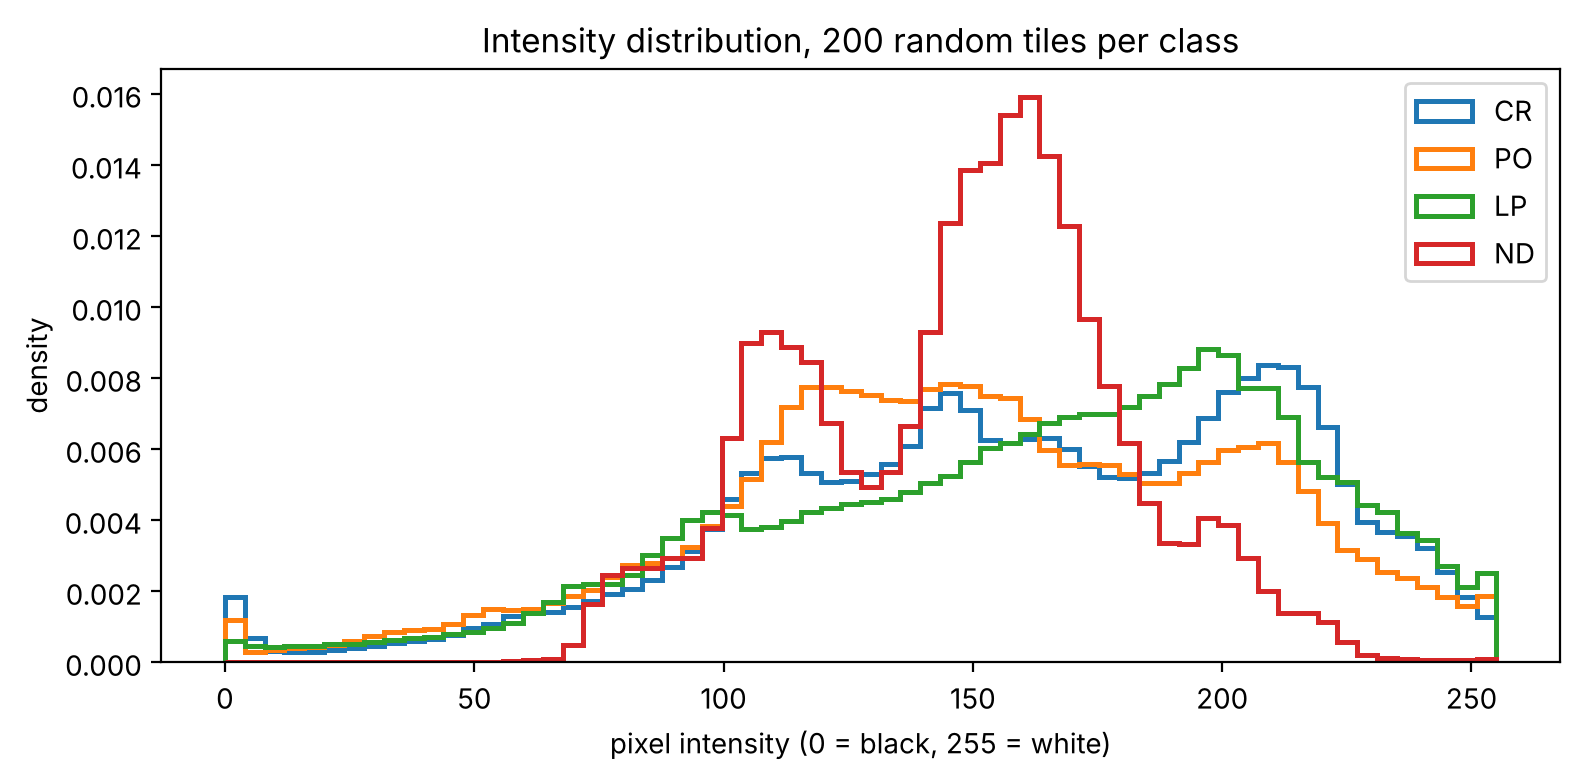

,class,mean,std,median
0,CR,159.500000,53.299999,163.0
1,PO,150.300003,51.599998,150.0
2,LP,162.100006,53.299999,170.0
3,ND,147.000000,32.700001,151.0


In [11]:
# Pixel-intensity histogram, 200 images per class
fig, ax = plt.subplots(figsize=(8, 4))
stats = []
for cls in ["CR", "PO", "LP", "ND"]:
    sub = table[table.label == cls].sample(200, random_state=SEED)
    px = np.concatenate([plt.imread(RIA / p).ravel() for p in sub.path]) * 255
    ax.hist(px, bins=64, range=(0, 255), density=True, histtype="step", lw=1.8, label=cls)
    stats.append({"class": cls, "mean": px.mean(), "std": px.std(), "median": np.median(px)})
ax.set_xlabel("pixel intensity (0 = black, 255 = white)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Intensity distribution, 200 random tiles per class")
plt.tight_layout(); plt.savefig(P.figures / "01_intensity_hist.png", dpi=130); plt.show()
pd.DataFrame(stats).round(1)

**Do the classes differ in brightness? Yes, in spread more than in mean.** Mean intensity is similar (147–162),
but ND tiles have a much narrower range (std ≈ 33 vs ≈ 52 for the defect classes) and almost no very dark or
very bright pixels. A model could therefore separate ND partly from brightness range alone, without "seeing"
a defect. Keep that in mind when Lab 9's Grad-CAM shows where models look.

## Notes (what I did, what I found, what surprised me)
- **Did:** extracted all 24,407 RIAWELC tiles, built `image_table.csv` (one row per tile, with source IDs parsed from file names and an MD5 per file), counted classes per split, viewed samples and intensity histograms.
- **Found:** classes are moderately imbalanced (CR 31%, PO 26%, ND 25%, LP 18%); the lazy "always CR" model scores 31.3%, so that is the floor. The official split is a stratified 65/25/10 with identical class shares in every split.
- **Found:** every tile comes from one of only 29 source plates (109 radiograph sections), named RRT-xxR, i.e. BAM Round Robin Test radiographs, the same source GDXray uses.
- **Surprised me:** tiles are 227×227, not the documented 224×224; 30 files are marked " - Copia" (copies); ND tiles have a visibly narrower brightness range than defect tiles.